# Implementation of TMSE-BioCRNpyler Modules: Thresholding

This notebook demonstrates how to model different thresholding behaviors using the TMSE-BioCRNpyler library, based on examples from Programming Cell-free Biosensors with DNA Strand Displacement Circuits ([Jung et al. *Nature Chemical Biology* 2022](https://www.nature.com/articles/s41589-021-00962-9)). It highlights how specific TMSE modules (introduced in Figure 2A) can be assembled to execute precise signal processing operations—such as NOT logic and timing delays—in response to a small molecule input (Tet).

## Supplementary Figure Simulations:
* [NOT Operation (Hairpin Threshold)](#ROSALIND-+-TMSE:-NOT-circuit): Simulates a circuit executing a NOT operation on a Tet input. The threshold, designed as a hairpin in the original study, is modeled here as a dsRNA Threshold without an RNA maturation step.
* [Timing Operation (DNA Threshold)](#ROSALIND-+-TMSE:-Threshold-timer-circuit): Simulates a timing circuit where a DNA Threshold is added at a fixed initial concentration rather than being produced transcriptionally. As the threshold concentration increases, the system requires more time to produce a measurable signal.

## Dependencies and packages

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
from matplotlib.ticker import FormatStrFormatter
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

## Global variables and definitions

In [2]:
# Simulate all models - example for 6 hours
timepoints = np.linspace(0,4,1001)*3600 

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (6, 6)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']


#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 20
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (hr)',fontsize=fs)
    plt.legend(title='Input',frameon=False, 
               title_fontsize = fs-4, fontsize=fs-4)

    plt.ylim(ymin,ymax)
    plt.xlim(0,4)
    plt.xticks(ticks=[0,1,2,3,4],fontsize=fs)
    plt.yticks(ticks=[0,1,2,3,4,5],fontsize=fs)
    
    # Setting the same number of decimal places for y-axis
    ax1 = plt.gca()
    ax1.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

    
    # Save plot as svg
    plt.savefig(f'{figs_dir}/SI_{fig_name}.svg')

## ROSALIND + TMSE: NOT circuit

In [3]:
# Define initial DNA and Reporter RNA

# Components
step_tx_reg = StrandExchangeMol({'TG{1,}': ['TGate',1]}, transcription=True)
step_tx_unreg = StrandExchangeMol({'I{1,}': ['Input',1]}, material_type= 'dna', transcription=True)
sd_dna = StrandExchangeMol({'R{1,}':['Reporter', 1]}, material_type= 'dna',)

step_tmse = TMSE([sd_dna.mol,step_tx_reg.rna,step_tx_unreg.rna])
# step_tmse = TMSE([sim_dna,step_tx.rna])

# Repressors
TetR = Species("TetR", material_type = "protein")

# Create a custom set of parameters
hill_parameters = {"k":0.1, "n":4, "K":60, "kleak":.00001}

# P_repressible
P_repressible = RepressiblePromoter("P_repressible", repressor  = TetR, leak = True, parameters = hill_parameters)

# DNA assembly (that produces rna_TG_1)
TetR_repressible_assembly = DNAassembly(name="TetR_repressible_assembly", promoter=P_repressible, rbs=None, transcript=step_tx_reg.rna,protein = None)

# Activators and complxes
aTc = Species("aTc", material_type = "small_molecule")
aTc_TetR= ChemicalComplex(species=[aTc, TetR])

# Reactions
# Mechanism binding
mech_bind = One_Step_Binding()
binding_mechanisms = {mech_bind.mechanism_type:mech_bind}
# # Mechanism tx 
mech_tx = mech_tl = SimpleTranscription()
tx_mechanisms = {mech_tx.mechanism_type:mech_tx}
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}


TMSE_parameters = {"ktx":3e-02,
                   "leak_percentage":0.3, 
                   "krep":4e-06,
                   "kth":8e-05, 
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_TetR_small_molecule_aTc", name = "kb"):4e-3,
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_TetR_small_molecule_aTc", name = "ku"):0.022,
                   }

# Make Mixture and Compile
M_txTMSEnotV2 = Mixture("txTMSEnotV2", 
                       components=[TetR_repressible_assembly, aTc_TetR, step_tmse, step_tx_unreg.mol], # [step_tx] switched for avtivatable promoter.#    Mixture specified
                       parameters=TMSE_parameters,
                       mechanisms=binding_mechanisms|tx_mechanisms|sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_txTMSEnotV2 = M_txTMSEnotV2.compile_crn()

# Print CRN reactions
print(CRN_txTMSEnotV2.pretty_print(show_rates = True, show_attributes = True, 
                                  show_materials = True, show_keys = False))


Species(N = 12) = {
complex[protein[TetR]:small_molecule[aTc]] (@ 0),  small_molecule[aTc] (@ 0),  rna[Waste_1_1] (@ 0),  rna[Waste_1] (@ 0),  dna[TetR_repressible_assembly] (@ 0),  protein[TetR] (@ 0),  rna[TGate_1] (@ 0),  dna[Signal_1(ss)] (@ 0),  dna[Reporter_1] (@ 0),  rnadna[ReporterOut_1] (@ 0),  dna[Input_1] (@ 0),  rna[Input_1] (@ 0),  
}

Reactions (6) = [
0. dna[TetR_repressible_assembly] --> dna[TetR_repressible_assembly]+rna[TGate_1]
 Kf = k dna[TetR_repressible_assembly] / ( 1 + (protein[TetR]/K)^4 )
  k=0.1
  K=60
  n=4

1. dna[TetR_repressible_assembly] --> dna[TetR_repressible_assembly]+rna[TGate_1]
 Kf=k_forward * dna_TetR_repressible_assembly
  k_forward=1e-05

2. protein[TetR]+small_molecule[aTc] <--> complex[protein[TetR]:small_molecule[aTc]]
 Kf=k_forward * protein_TetR * small_molecule_aTc
 Kr=k_reverse * complex_protein_TetR_small_molecule_aTc_
  k_forward=0.004
  k_reverse=0.022

3. rna[Input_1]+rna[TGate_1] --> rna[Waste_1]+rna[Waste_1_1]
 Kf=k_forward * rna_I

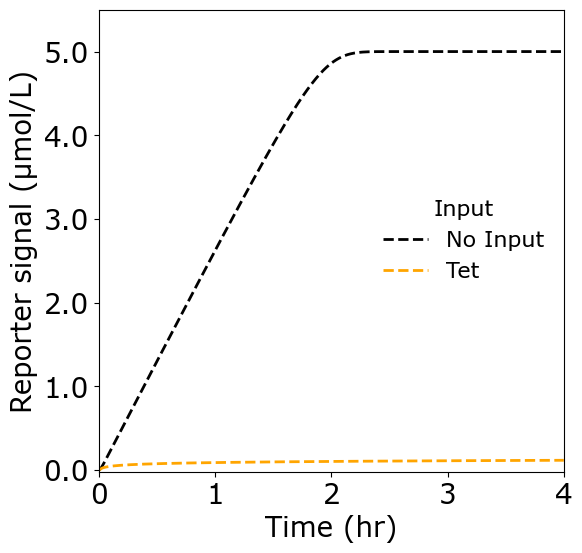

In [4]:
# Simulate
try:
    import pylab as plt

    # Input templates
    Tet_conc = [0,1]

    idx_conditions = {'No Input':['black', '--'],
                      'Tet': ['orange','--'],}

    for Tet, key in zip(Tet_conc,idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': 25, 
                                      'dna_TetR_repressible_assembly':100,
                                      'dna_Reporter_1':5*1000,
                                      'protein_TetR':5000, 'small_molecule_aTc':20e3*Tet}
                                      
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_txTMSEnotV2.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                             initial_condition_dict = initial_concentration_dict)
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_1_ss']/1000, label=key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Reporter signal (μmol/L)',ymax = 5.5, fig_name= 'ROSALIND_NOT2')  

## ROSALIND + TMSE: Threshold timer circuit 
Based on example ([Jung et al., 2022, Fig. 6b](https://www.nature.com/articles/s41589-021-00962-9))

In [5]:
# Define initial DNA and Reporter RNA

# Components
step_tx = StrandExchangeMol({'I{1,}': ['Input',1]}, material_type= 'dna', transcription=True)
sd_dna = StrandExchangeMol({'R{1,}':['Reporter', 1],'TG{1,}': ['TGate',1]}, material_type= 'dna')

step_tmse = TMSE([sd_dna.mol,step_tx.rna])
# step_tmse = TMSE([sim_dna,step_tx.rna])

# # Mechanism tx 
mech_tx = mech_tl = SimpleTranscription()
tx_mechanisms = {mech_tx.mechanism_type:mech_tx}
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}


TMSE_parameters = {"ktx":1e-01,
                   "krep":4e-05,
                   "kth":4e-03, 
                    }

# Make Mixture and Compile
M_txTMSEthresh = Mixture("txTMSEthresh", 
                       components=[step_tmse,step_tx.mol], # [step_tx] switched for avtivatable promoter.#    Mixture specified
                       parameters=TMSE_parameters,
                       mechanisms=tx_mechanisms|sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_txTMSEthresh = M_txTMSEthresh.compile_crn()

# Print CRN reactions
print(CRN_txTMSEthresh.pretty_print(show_rates = True, show_attributes = True, 
                                  show_materials = True, show_keys = False))


Species(N = 8) = {
dnarna[Waste_1_1] (@ 0),  dnarna[Waste_1] (@ 0),  dna[TGate_1] (@ 0),  dna[Signal_1(ss)] (@ 0),  dna[Reporter_1] (@ 0),  rnadna[ReporterOut_1] (@ 0),  dna[Input_1] (@ 0),  rna[Input_1] (@ 0),  
}

Reactions (3) = [
0. rna[Input_1]+dna[TGate_1] --> dnarna[Waste_1]+dnarna[Waste_1_1]
 Kf=k_forward * rna_Input_1 * dna_TGate_1
  k_forward=0.004

1. rna[Input_1]+dna[Reporter_1] --> dna[Signal_1(ss)]+rnadna[ReporterOut_1]
 Kf=k_forward * rna_Input_1 * dna_Reporter_1
  k_forward=4e-05

2. dna[Input_1] --> dna[Input_1]+rna[Input_1]
 Kf=k_forward * dna_Input_1
  k_forward=0.1

]


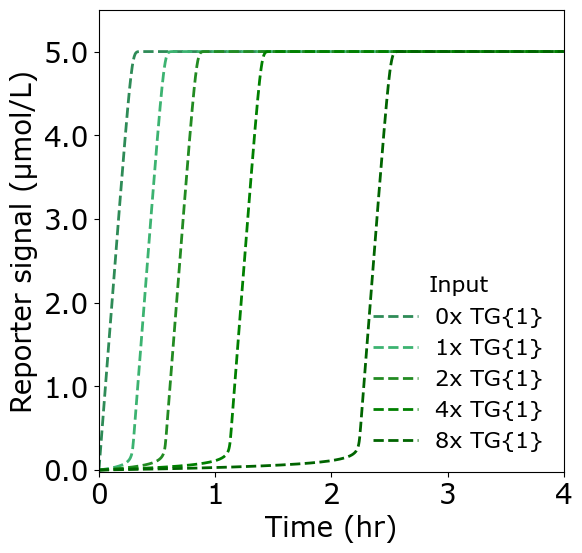

In [6]:
# Simulate
try:
    import pylab as plt

    # Input templates
    TG_conc = [0,1,2,4,8]

    idx_conditions = {'0x TG{1}':['seagreen', '--'],
                      '1x TG{1}':['mediumseagreen', '--'],
                      '2x TG{1}':['forestgreen', '--'],
                      '4x TG{1}':['green', '--'],
                      '8x TG{1}':['darkgreen', '--'],}

    for TG, key in zip(TG_conc,idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Input_1': 50, 
                                      'dna_TGate_1':TG*5000,
                                      'dna_Reporter_1':5000}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_txTMSEthresh.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                        initial_condition_dict = initial_concentration_dict)
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_1_ss']/1000, label = key,
                 color = idx_conditions[key][0],linewidth = 2,linestyle = idx_conditions[key][1])
        
        plt.xlim(0,4)
        
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Reporter signal (μmol/L)',ymax = 5.5, fig_name= 'ROSALIND_Thresh') 

# Computing environment

In [7]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

